<a href="https://colab.research.google.com/github/encen-ya/ML_2026/blob/main/Pertemuan_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Praktikum 1
### k-Nearest Neighbors (kNN)



In [1]:
from google.colab import files
uploaded = files.upload()

Saving iris (1).csv to iris (1).csv


### Langkah 1

In [6]:
	# Load data
	import pandas as pd
	data = pd.read_csv('iris (1).csv')
	data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Langkah 2

In [7]:
	data.info()
	data.describe()
	data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


### Langkah 3

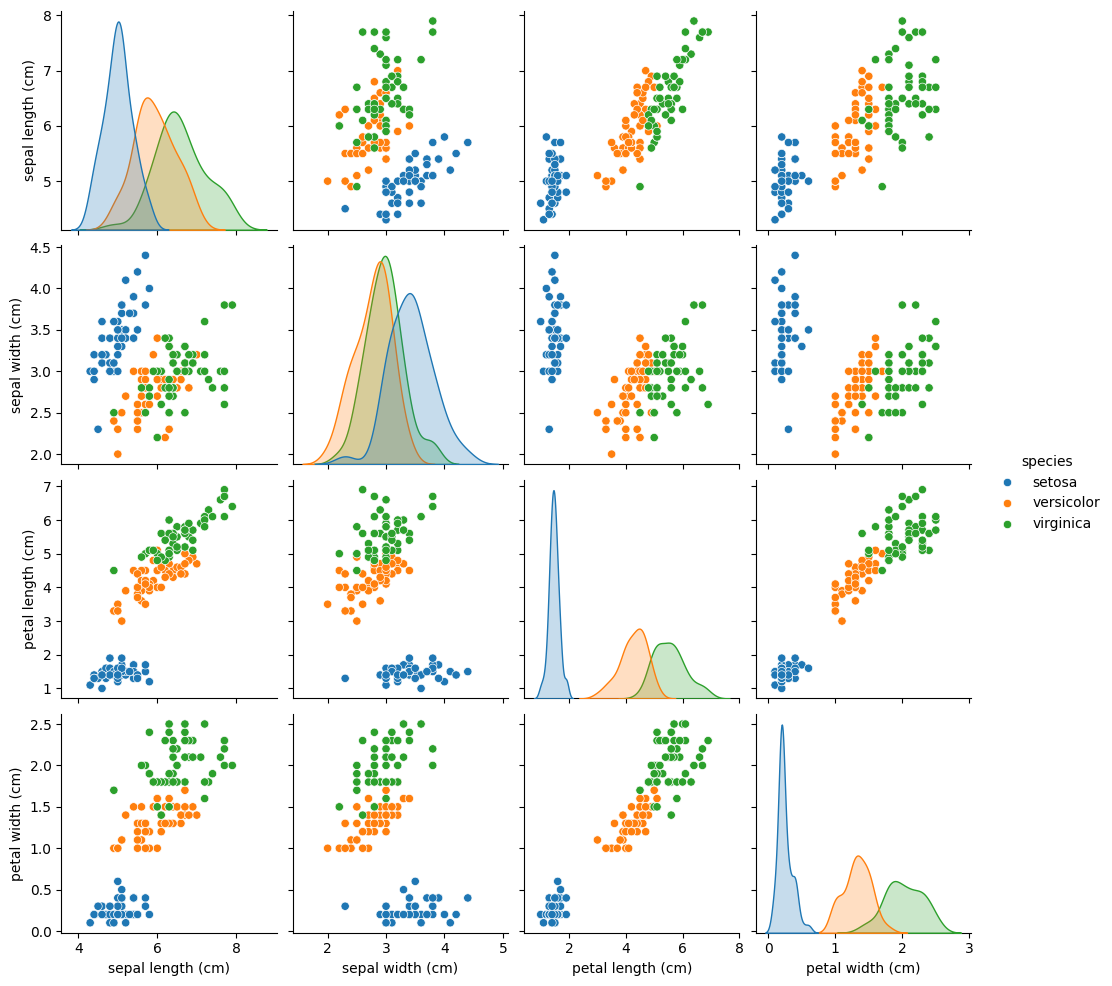

In [8]:
	import seaborn as sns
	import matplotlib.pyplot as plt

	sns.pairplot(data, hue='species')
	plt.show()


### Langkah 4

In [9]:
	from sklearn.model_selection import train_test_split
	from sklearn.preprocessing import StandardScaler

	X = data.iloc[:, :-1]   # semua kolom kecuali label
	y = data.iloc[:, -1]    # kolom label terakhir

	# Split data (70% train, 30% test)
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

	# Standardisasi
	scaler = StandardScaler()
	X_train = scaler.fit_transform(X_train)
	X_test = scaler.transform(X_test)

### Langkah 5

In [10]:
	from sklearn.neighbors import KNeighborsClassifier

	# Tentukan nilai K (misalnya 3)
	knn = KNeighborsClassifier(n_neighbors=3)

	# Latih model
	knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

Langkah 6

In [11]:
	from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

	y_pred = knn.predict(X_test)
	print("Akurasi:", accuracy_score(y_test, y_pred))
	print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
	print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



Langkah 7

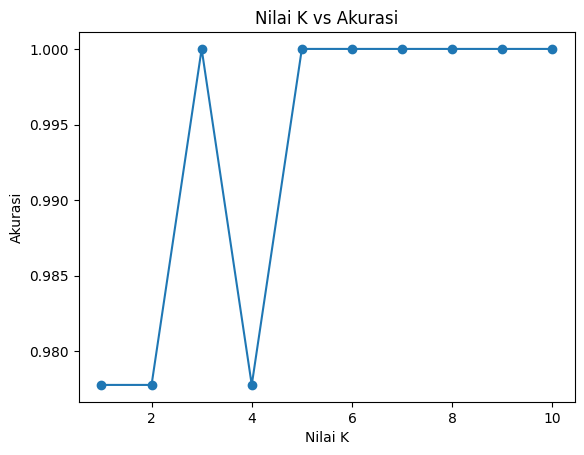

In [12]:
	acc = []
	for k in range(1, 11):
	    model = KNeighborsClassifier(n_neighbors=k)
	    model.fit(X_train, y_train)
	    acc.append(model.score(X_test, y_test))

	plt.plot(range(1, 11), acc, marker='o')
	plt.title('Nilai K vs Akurasi')
	plt.xlabel('Nilai K')
	plt.ylabel('Akurasi')
	plt.show()


# Praktikum 2

### Langkah 1 - Buat Dataset Du

In [13]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[ 95 123]
 [126  16]
 [ 78 172]
 [135  18]
 [108  78]
 [124  25]
 [144  40]
 [111  64]
 [284 131]
 [124 111]
 [110  51]
 [ 10  64]
 [ 13 109]
 [123 111]
 [165 140]
 [ 82 134]
 [ 56  65]
 [ 81  89]
 [ 74  78]
 [147 133]
 [ 99  99]
 [ 25  40]
 [ 70  73]
 [114 110]
 [146  92]
 [  1  95]
 [ 18  80]
 [131  99]
 [121  84]
 [ 76  90]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


### Langkah 2 (Opsional) - Membuat Data Frame


In [14]:
	import pandas as pd

	# Reshape label y menjadi 2D
	# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
	y_new = y.reshape(len(y), 1)

	# Gabungkan fitur X dan label y dalam data array
	data = np.concatenate((X, y_new), axis=1)

	# Definisikan nama kolom
	nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

	# Buat Data Frame
	df = pd.DataFrame(data, columns=nama_kolom)

	# Cek Data Frame
	df.head()

,Fitur 1,Fitur 2,Label
0,95,123,0
1,126,16,0
2,78,172,0
3,135,18,0
4,108,78,0


### Langkah 3 (Opsional) - Labeling


In [15]:
	# Definisikan nama label
	labels = {
	    1 : 'Kelas A',
	    0 : 'Kelas B'
	}

	# Copy Data Frame untuk menyimpan Data Frame baru
	# dengan label yang mudah untuk dibaca
	df_label = df.copy()

	# Ubah label dengan fungsi mapping dari Pandas
	# pada Data Frame df_label
	df_label['Label'] = df_label['Label'].map(labels)

	# Cek Data Frame df_label
	df_label.head()

,Fitur 1,Fitur 2,Label
0,95,123,Kelas B
1,126,16,Kelas B
2,78,172,Kelas B
3,135,18,Kelas B
4,108,78,Kelas B


Langkah 4 - Visualisasi Data



/tmp/ipykernel_812/1912510248.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_812/1912510248.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


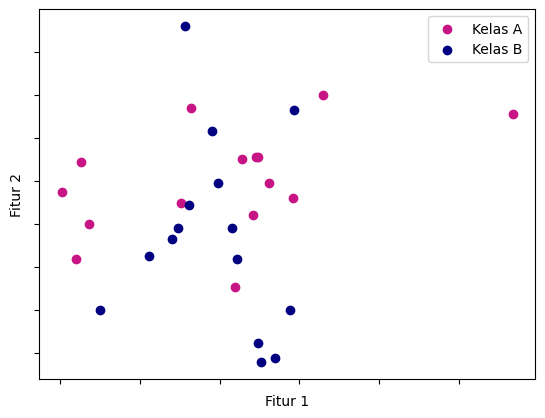

In [16]:
	import matplotlib.pyplot as plt

	# Definisikan warna untuk setiap kelas
	colors = {
	    'class_a': 'MediumVioletRed',
	    'class_b': 'Navy'
	}

	# Kelompokkan label berdasarkan nama kelas
	gb = df_label.groupby(['Label'])
	class_a = gb.get_group('Kelas A')
	class_b = gb.get_group('Kelas B')

	# Plot
	plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
	plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
	plt.xlabel('Fitur 1')
	plt.ylabel('Fitur 2')
	plt.legend(['Kelas A', 'Kelas B'])
	plt.gca().axes.xaxis.set_ticklabels([])
	plt.gca().axes.yaxis.set_ticklabels([])
	plt.show()

### Langkah 5 - Model Multinomial Naive Bayes


In [17]:
	from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

	# Inisiasi obyek MultinomialNB
	mnb = MultinomialNB()

	# Kita dapat langsung menggunakan fitur X dan label y
	# hasil dari proses pembuatan data dummy

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit model
	# Label y harus dalam bentuk 1D atau (n_samples,)
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred = mnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train = accuracy_score(y_train, y_train_pred)

	# Prediksi test data
	y_test_pred = mnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.47619047619047616
Hasil akurasi data test: 0.4444444444444444


### Langkah 6 - Model Gaussian Naive Bayes


In [18]:
	from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

	# Inisiasi obyek Gaussian
	gnb = GaussianNB()

	# Kita menggunakan split data training dan testing
	# yang sama dengan model multinomial

	# Fit model
	# Label y harus dalam bentu 1D atau (n_samples,)
	gnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred_gnb = gnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

	# Prediksi test data
	y_test_pred_gnb = gnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
	print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.8571428571428571
Hasil akurasi data test (Gaussian): 0.5555555555555556


# Praktikum 3

### Langkah 1 - Load Data


In [20]:
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam.csv


In [21]:
	import numpy as np
	import pandas as pd

	df = pd.read_csv('spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

	df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


### Langkah 2 - Preprocessing
Beberapa hal yang akan dilakukan pada tahap ini yaitu,

Drop kolom yang tidak digunakan

Ubah nama kolom v1 (label) dan v2 (teks sms)

Inspeksi Data

Encode label

Memisahkan fitur dengan label

### Langkah 2a - Drop Kolom

In [22]:
	# Drop 3 kolom terakhir dengan fungsi iloc
	df = df.drop(df.iloc[:,2:], axis=1)

	# Cek data
	df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Langkah 2b - Inspeksi Data



In [24]:
	# Cek Jumlah Data Per Kelas
	print(df['v1'].value_counts())
	print('\n')

	# Cek Kelengkapan Data
	print(df.info())
	print('\n')

	# Cek Statistik Deskriptif
	print(df.describe())

v1
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


          v1                      v2
count   5572                    5572
unique     2                    5169
top      ham  Sorry, I'll call later
freq    4825                      30


### Langkah 2c - Encoding Label


In [27]:
	# Ubah nama kolom v1 menjadi Labels dan v2 menjadi SMS
	df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})

	# Data untuk label
	new_labels = {
	    'spam': 1,
	    'ham': 0
	}

	# Encode label
	df['Labels'] = df['Labels'].map(new_labels)

	# Cek data
	df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


### Langkah 2d - Pisahkan Fitur dengan Label



In [28]:
	X = df['SMS'].values
	y = df['Labels'].values

### Langkah 3 - Ekstraksi Fitur


In [29]:
	from sklearn.model_selection import train_test_split
	from sklearn.feature_extraction.text import CountVectorizer

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

	# Inisiasi CountVectorizer
	bow = CountVectorizer()

	# Fitting dan transform X_train dengan CountVectorizer
	X_train = bow.fit_transform(X_train)

	# Transform X_test
	# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
	# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
	# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
	X_test = bow.transform(X_test)

In [31]:
	print(len(bow.get_feature_names_out()))
	print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


### Langkah 4 - Training dan Evaluasi Model


In [33]:
	from sklearn.naive_bayes import MultinomialNB
	from sklearn.metrics import accuracy_score

	# Inisiasi MultinomialNB
	mnb = MultinomialNB()

	# Fit model
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_pred_train = mnb.predict(X_train)

	# Evaluasi akurasi data training
	acc_train = accuracy_score(y_train, y_pred_train)

	# Prediksi dengan data training
	y_pred_test = mnb.predict(X_test)

	# Evaluasi akurasi data training
	acc_test = accuracy_score(y_test, y_pred_test)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


# Tugas 1

In [34]:
from google.colab import files
uploaded = files.upload()

Saving voice.csv to voice.csv


(3168, 21)
label
male      1584
female    1584
Name: count, dtype: int64
0


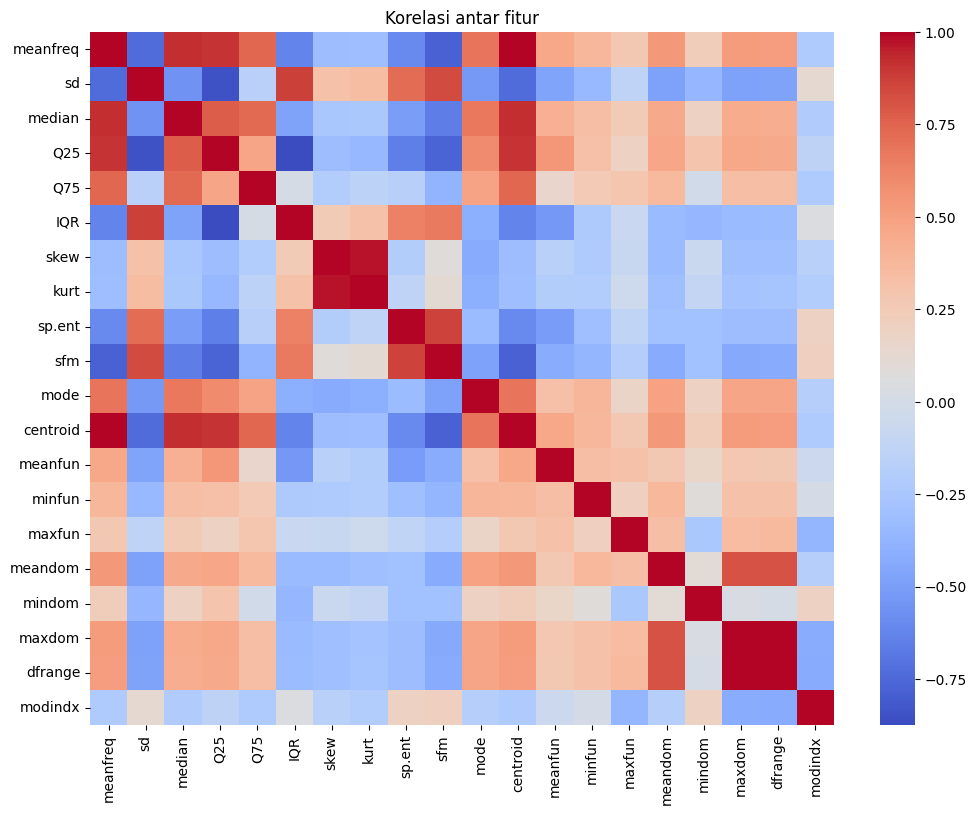

Akurasi baseline (semua fitur): 0.9737118822292324
[[461  15]
 [ 10 465]]
              precision    recall  f1-score   support

      female       0.98      0.97      0.97       476
        male       0.97      0.98      0.97       475

    accuracy                           0.97       951
   macro avg       0.97      0.97      0.97       951
weighted avg       0.97      0.97      0.97       951

meanfun     0.552268
IQR         0.443463
Q25         0.405638
sd          0.302157
mode        0.182577
sp.ent      0.160691
sfm         0.132118
meanfreq    0.120140
centroid    0.120140
mindom      0.090520
maxdom      0.086270
skew        0.080388
dfrange     0.069710
median      0.069636
meandom     0.048421
kurt        0.045627
minfun      0.026533
maxfun      0.019067
modindx     0.009172
Q75         0.000000
dtype: float64
    n_fitur  cv_akurasi
0         1    0.941814
1         2    0.966175
2         3    0.972031
3         4    0.974291
4         5    0.976544
5         6    0.974

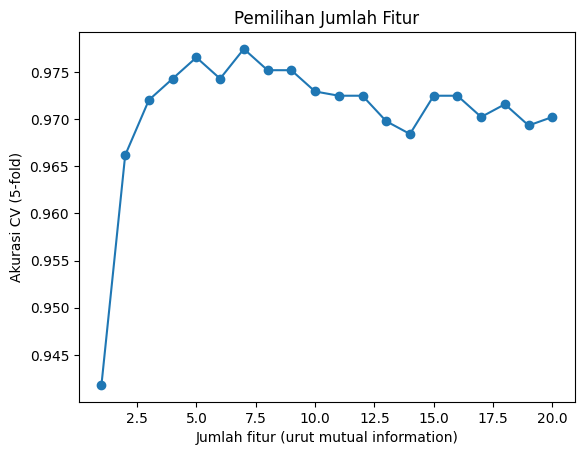

k terbaik: 5


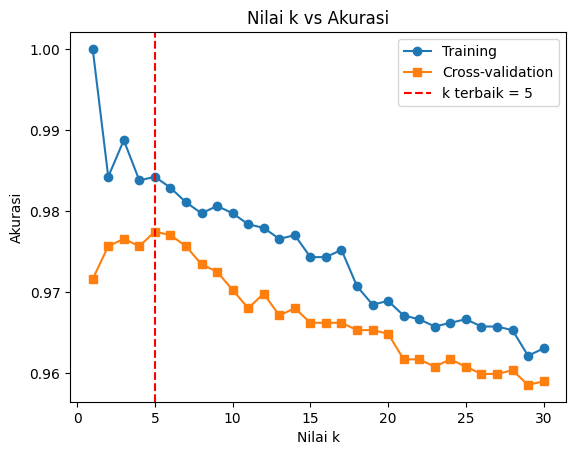

Akurasi akhir (data test): 0.9842271293375394
[[468   8]
 [  7 468]]
              precision    recall  f1-score   support

      female       0.99      0.98      0.98       476
        male       0.98      0.99      0.98       475

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ===== Load & eksplorasi =====
df = pd.read_csv('voice.csv')
print(df.shape)
print(df['label'].value_counts())
print(df.isnull().sum().sum())

X = df.drop('label', axis=1)
y = df['label']          # 'male' / 'female'

plt.figure(figsize=(12, 9))
sns.heatmap(X.corr(), cmap='coolwarm')
plt.title('Korelasi antar fitur')
plt.show()

# Split (stratify agar proporsi kelas terjaga)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# ===== 1. Model kNN dengan semua fitur (baseline) =====
base = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
base.fit(X_train, y_train)
y_pred = base.predict(X_test)
print("Akurasi baseline (semua fitur):", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

# ===== 2. Cari fitur paling optimal =====
# Peringkat fitur berdasarkan mutual information (hanya data latih)
mi = mutual_info_classif(X_train, y_train, random_state=42)
ranking = pd.Series(mi, index=X.columns).sort_values(ascending=False)
print(ranking)

# Uji top-n fitur dengan 5-fold cross validation pada data latih
hasil = []
for n in range(1, len(ranking) + 1):
    fitur = ranking.index[:n]
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    skor = cross_val_score(pipe, X_train[fitur], y_train, cv=5).mean()
    hasil.append((n, skor))

hasil_df = pd.DataFrame(hasil, columns=['n_fitur', 'cv_akurasi'])
n_best = int(hasil_df.loc[hasil_df['cv_akurasi'].idxmax(), 'n_fitur'])
fitur_terbaik = list(ranking.index[:n_best])
print(hasil_df)
print("Jumlah fitur terbaik:", n_best)
print("Fitur terbaik:", fitur_terbaik)

plt.plot(hasil_df['n_fitur'], hasil_df['cv_akurasi'], marker='o')
plt.xlabel('Jumlah fitur (urut mutual information)')
plt.ylabel('Akurasi CV (5-fold)')
plt.title('Pemilihan Jumlah Fitur')
plt.show()

# ===== 3. Cari nilai k terbaik pada fitur terpilih =====
k_range = range(1, 31)
cv_acc, train_acc = [], []
for k in k_range:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_acc.append(cross_val_score(pipe, X_train[fitur_terbaik], y_train, cv=5).mean())
    pipe.fit(X_train[fitur_terbaik], y_train)
    train_acc.append(pipe.score(X_train[fitur_terbaik], y_train))

k_best = list(k_range)[int(np.argmax(cv_acc))]
print("k terbaik:", k_best)

plt.plot(k_range, train_acc, marker='o', label='Training')
plt.plot(k_range, cv_acc, marker='s', label='Cross-validation')
plt.axvline(k_best, color='r', linestyle='--', label=f'k terbaik = {k_best}')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.title('Nilai k vs Akurasi')
plt.legend()
plt.show()

# ===== Evaluasi akhir pada data test =====
final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_best))
final.fit(X_train[fitur_terbaik], y_train)
y_pred = final.predict(X_test[fitur_terbaik])

print("Akurasi akhir (data test):", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Tugas 2

===== CountVectorizer (stop_words) =====
Jumlah fitur: 7466
Akurasi train: 0.9946152120260264
Akurasi test : 0.9829596412556054
Confusion Matrix:
 [[951   3]
 [ 16 145]]
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



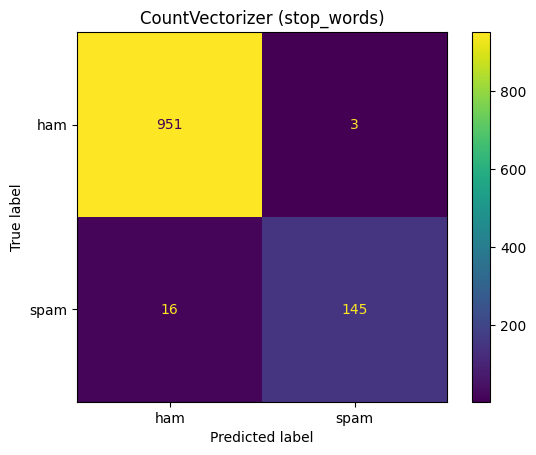

===== TF-IDF (stop_words) =====
Jumlah fitur: 7466
Akurasi train: 0.9842943684092439
Akurasi test : 0.9605381165919282
Confusion Matrix:
 [[954   0]
 [ 44 117]]
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



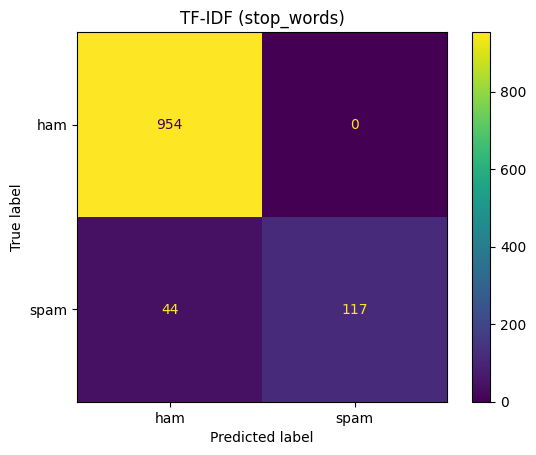

                              Accuracy  Precision (spam)  Recall (spam)  \
Fitur                                                                     
CountVectorizer (stop_words)    0.9830            0.9797         0.9006   
TF-IDF (stop_words)             0.9605            1.0000         0.7267   

                              F1 (spam)  
Fitur                                    
CountVectorizer (stop_words)     0.9385  
TF-IDF (stop_words)              0.8417  


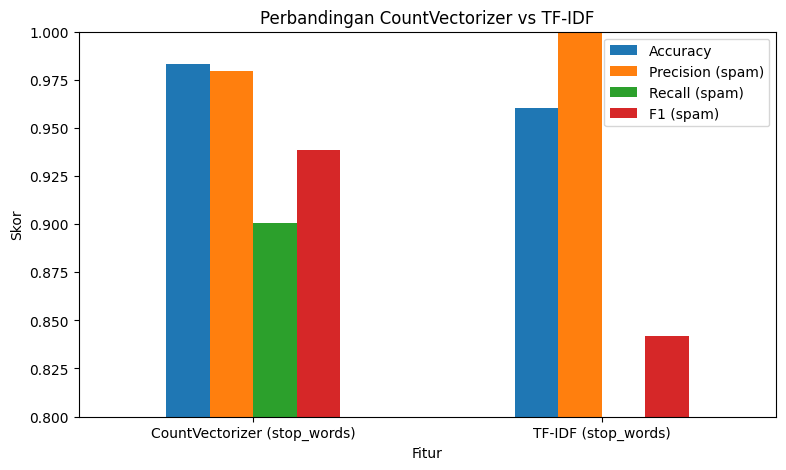

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

# Load & preprocessing (sama seperti Praktikum 3)
df = pd.read_csv('spam.csv', encoding='latin-1')
df = df.drop(df.iloc[:, 2:], axis=1)
df.columns = ['Labels', 'SMS']
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})

X = df['SMS'].values
y = df['Labels'].values

# Split yang sama untuk kedua model agar perbandingan adil
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50)

def evaluasi(nama, vectorizer):
    Xtr = vectorizer.fit_transform(X_train_txt)   # fit hanya di data latih
    Xte = vectorizer.transform(X_test_txt)
    model = MultinomialNB()
    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)

    print(f"===== {nama} =====")
    print("Jumlah fitur:", Xtr.shape[1])
    print("Akurasi train:", accuracy_score(y_train, model.predict(Xtr)))
    print("Akurasi test :", accuracy_score(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['ham', 'spam'])
    plt.title(nama)
    plt.show()

    return {
        'Fitur': nama,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (spam)': precision_score(y_test, y_pred),
        'Recall (spam)': recall_score(y_test, y_pred),
        'F1 (spam)': f1_score(y_test, y_pred),
    }

# Tugas 2a: CountVectorizer + stop_words
hasil_bow = evaluasi('CountVectorizer (stop_words)', CountVectorizer(stop_words='english'))

# Tugas 2b: TF-IDF + stop_words
hasil_tfidf = evaluasi('TF-IDF (stop_words)', TfidfVectorizer(stop_words='english'))

# Perbandingan
perbandingan = pd.DataFrame([hasil_bow, hasil_tfidf]).set_index('Fitur')
print(perbandingan.round(4))

perbandingan.plot(kind='bar', figsize=(9, 5), ylim=(0.8, 1.0))
plt.title('Perbandingan CountVectorizer vs TF-IDF')
plt.ylabel('Skor')
plt.xticks(rotation=0)
plt.show()